# HSA_Cam_B_018.py
This file uses the LHHW_Model of kinetics and FFD to determine kinetic parameters.

HSA_Cam_B_007.py is the model. This uses heteroscedastic noise of 10%  and exponential priors.

Analysis from the related python script.


In [1]:
import json
from pathlib import Path
import sys

sys.argv = [""]
import numpy as np
import matplotlib.pyplot as plt
import torch
import arviz as az
import ICIW_Plots

plt.style.use("ICIWstyle")

In [2]:
from HSA_Cam_B_018_pyro import (
    predict,
    generate_synthetic_data,
    calculate_partial_pressures,
    kl_divergence_between_models,
)
from HSA_Mo_B_007_pyro import kinetics_model, sample_prior, TRUE_PARAMS

In [3]:
def max_func(x, idata, key="posterior"):
    T = x[0].reshape(1, 1)
    p = x[1].reshape(1, 1)
    c2h = x[2].reshape(1, 1)
    f = x[3].reshape(1, 1)
    c2i = x[4].reshape(1, 1)
    p_i = calculate_partial_pressures(p, c2h, f, c2i)
    res = predict(
        idata,
        T,
        p_i,
        num_samples=1000,
        key=key,
    )
    HDI = torch.quantile(res, 0.975) - torch.quantile(res, 0.025)
    return -HDI

In [4]:
def evaluate_conditions(proposal, idata, key="posterior"):
    """
    Evaluate posterior predictions over temperature range at given conditions.

    Args:
        proposal: Array [T, p, c2h, f, c2i] defining experimental conditions
        idata: ArviZ InferenceData with posterior samples

    Returns:
        predictions: Array of shape (100, n_samples) with rate predictions
    """
    # Extract conditions from proposal
    p = torch.tensor([[proposal[1]]])
    c2h = torch.tensor([[proposal[2]]])
    f = torch.tensor([[proposal[3]]])
    c2i = torch.tensor([[proposal[4]]])

    # Calculate partial pressures
    p_i = calculate_partial_pressures(p, c2h, f, c2i)

    # Temperature range for evaluation
    T = torch.linspace(500.0, 600.0, 100).reshape(-1, 1)

    # Generate posterior predictions
    predictions = predict(idata, T, p_i, key=key, num_samples=1000)

    return predictions


def evaluate_true_model(proposal):
    """
    Compute true model predictions (for comparison with posterior).

    Args:
        proposal: Array [T, p, c2h, f, c2i] defining experimental conditions

    Returns:
        true_rates: Array of shape (100, 1) with true rate predictions
    """
    # Extract conditions
    p = torch.tensor([[proposal[1]]])
    c2h = torch.tensor([[proposal[2]]])
    f = torch.tensor([[proposal[3]]])
    c2i = torch.tensor([[proposal[4]]])

    # Calculate partial pressures
    p_i = calculate_partial_pressures(p, c2h, f, c2i)

    # Temperature range
    T = torch.linspace(500.0, 600.0, 100).reshape(-1, 1)

    # True model prediction
    _, _, true_rates = generate_synthetic_data(T, p, c2h, f, c2i, rel_noise_std=0.0)

    return true_rates.cpu().numpy()


def plot_predictions(fig, ax, proposal, posterior_preds, true_preds, T_range):
    """
    Visualize posterior predictions vs true model with uncertainty.

    Args:
        proposal: Experimental conditions [T, p, c2h, f, c2i]
        posterior_preds: Posterior predictions (100, n_samples)
        true_preds: True model predictions (100, 1)
        T_range: Temperature values for x-axis
    """

    # Posterior mean
    ax.plot(
        T_range,
        posterior_preds.mean(axis=1),
        label="Posterior Mean",
        # color="blue",
    )

    # True model
    ax.plot(
        T_range,
        true_preds.squeeze(),
        label="True Model",
        color="black",
        linestyle="--",
        linewidth=2,
    )

    # 95% credible interval
    ax.fill_between(
        T_range,
        np.percentile(posterior_preds, 2.5, axis=1),
        np.percentile(posterior_preds, 97.5, axis=1),
        alpha=0.3,
        # color="blue",
        label="95% HDI",
    )

    ax.legend(loc="upper left")

    # Add condition text
    # condition_text = (
    #     f"Conditions:\n"
    #     f"p = {proposal[1]:.1f} bar\n"
    #     f"CO2/H2 = {proposal[2]:.2f}\n"
    #     f"Feed ratio = {proposal[3]:.1f}\n"
    #     f"CO2/Inert = {proposal[4]:.2f}"
    # )
    # ax.text(
    #     0.02,
    #     0.8,
    #     condition_text,
    #     transform=ax.transAxes,
    #     fontsize=9,
    #     verticalalignment="top",
    #     bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.5),
    # )

    # Second y-axis for HDI width
    # ax2 = ax.twinx()
    # hdi_width = np.percentile(posterior_preds, 97.5, axis=1) - np.percentile(
    #     posterior_preds, 2.5, axis=1
    # )
    # ax2.plot(T_range, hdi_width, color="orange", alpha=0.7, linewidth=2)
    # ax2.set_ylabel("HDI Width", color="orange")
    # ax2.tick_params(axis="y", labelcolor="orange")

    # plt.title("Posterior Predictions vs True Model")
    # plt.tight_layout()
    return fig, ax

In [5]:
exp_run_name = "managing-loft"  # VI
data_path = Path(f"data/{exp_run_name}/")
sum_file = data_path / f"experiment_summary_{exp_run_name}.json"
trace_files = sorted(data_path.glob("trace_*.nc"))

In [6]:
idatas = []
for trace_file in trace_files:
    idata = az.from_netcdf(trace_file)
    idatas.append(idata)

In [7]:
for i, idata in enumerate(idatas):
    if i == 0:
        idata.add_groups({"prior": sample_prior(4000).prior})
    else:
        idata.add_groups({"prior": idatas[i - 1].posterior})

In [8]:
with open(sum_file, "r") as f:
    exp_summary = json.load(f)

In [9]:
proposals = np.array(exp_summary["trials"][-1]["observed"]["x"])
r_obs = np.array(exp_summary["trials"][-1]["observed"]["y"])

### Display the results:

In [10]:
from ipywidgets import interact, IntSlider


@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
    j=IntSlider(
        min=0, max=len(proposals) - 1, step=1, value=0, description="Proposal:"
    ),
)
def plot_interactive(i, j):
    fig = ICIW_Plots.figure(layout="double_column")
    ax = ICIW_Plots.make_rect_ax(
        fig,
        ax_width=7.5 * ICIW_Plots.cm2inch,
        ax_height=5.0 * ICIW_Plots.cm2inch,
        xlabel="$T$ / K",
        ylabel="$r$ / mol g$^{-1}$ s$^{-1}$",
    )
    test_res = evaluate_conditions(
        proposal=proposals[j],
        idata=idatas[i],
        key="posterior" if i > 0 else "prior",
    )
    true_res = evaluate_true_model(
        proposal=proposals[j],
    )
    plot_predictions(
        fig,
        ax,
        proposal=proposals[j],
        posterior_preds=test_res,
        true_preds=true_res,
        T_range=np.linspace(500, 600, 100),
    )
    fig = plt.gcf()
    axs = fig.axes
    axs[0].set(
        ylim=(0, 0.0006),
        xlabel="$T$ / K",
        xlim=(500, 600),
    )
    axs[0].scatter(
        proposals[j, 0], r_obs[j], color="red", label="Observed Data Point", zorder=5
    )
    plt.show()

interactive(children=(IntSlider(value=0, description='Iteration:', max=31), IntSlider(value=0, description='Pr…

### Generate the exploration pattern

C:\Users\hanne\AppData\Local\Temp\ipykernel_22824\2292498082.py:81: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



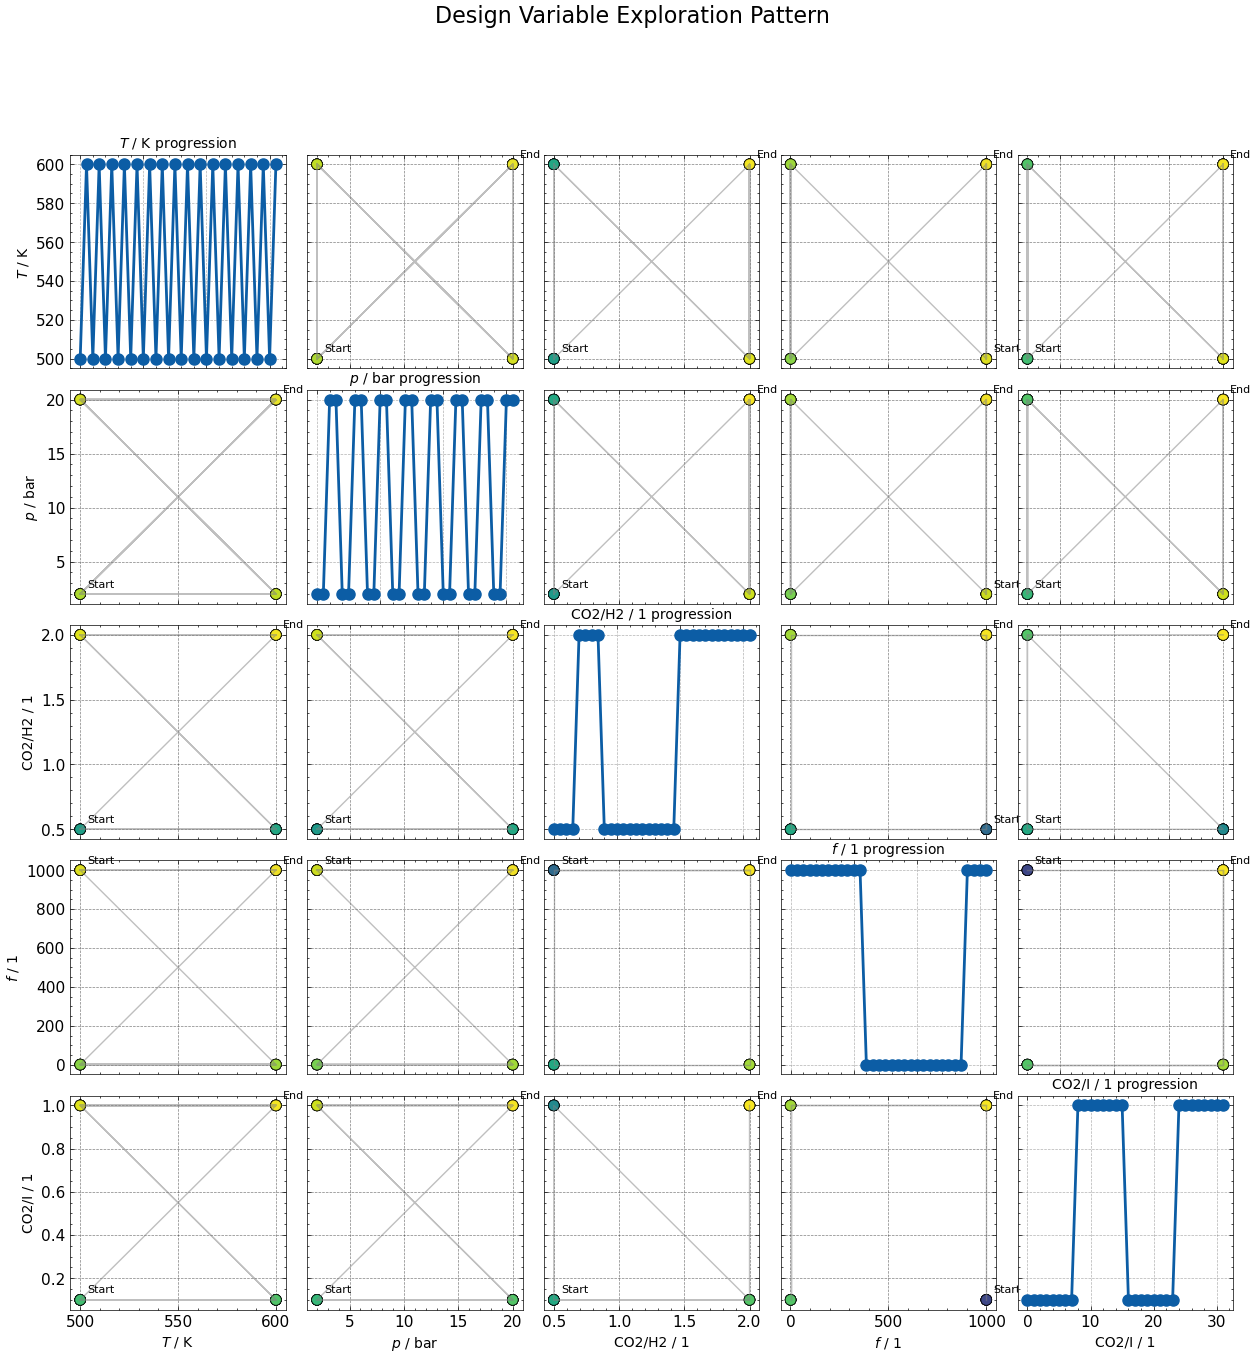

In [11]:
# create a 5x5 matrix plot with no gaps between the subplots
fig, axs = plt.subplots(
    5,
    5,
    figsize=(15, 15),
    sharex=False,
    sharey=False,
    gridspec_kw={"hspace": 0.1, "wspace": 0.1},
)

# Variable names for labeling
var_names = [r"$T$ / K", r"$p$ / bar", r"CO2/H2 / 1", r"$f$ / 1", r"CO2/I / 1"]

# Assuming proposals array exists with shape (n_experiments, 5)
n_experiments = proposals.shape[0]
experiment_order = np.arange(n_experiments)

for i in range(5):
    for j in range(5):
        ax = axs[i, j]

        if i == j:  # Diagonal: time series of each variable
            ax.plot(experiment_order, proposals[:, i], "o-", linewidth=2, markersize=8)
            ax.set_title(f"{var_names[i]} progression", fontsize=10, pad=5)
            ax.grid(True, alpha=0.3)
            if i == 4:  # Bottom row
                ax.set_xlabel("Experiment #")
        else:  # Off-diagonal: scatter plots
            # Color points by experiment order for temporal information
            scatter = ax.scatter(
                proposals[:, j],
                proposals[:, i],
                c=experiment_order,
                cmap="viridis",
                s=60,
                alpha=0.8,
                edgecolors="black",
                linewidth=0.5,
            )

            # Add trajectory lines
            ax.plot(
                proposals[:, j],
                proposals[:, i],
                "-",
                alpha=0.5,
                color="gray",
                linewidth=1,
            )

            # Label first and last points
            ax.annotate(
                "Start",
                (proposals[0, j], proposals[0, i]),
                xytext=(5, 5),
                textcoords="offset points",
                fontsize=8,
            )
            if n_experiments > 1:
                ax.annotate(
                    "End",
                    (proposals[-1, j], proposals[-1, i]),
                    xytext=(5, 5),
                    textcoords="offset points",
                    fontsize=8,
                )

        # Set labels only on edges
        if i == 4:  # Bottom row
            ax.set_xlabel(var_names[j], fontsize=10)
        if j == 0:  # Left column
            ax.set_ylabel(var_names[i], fontsize=10)

        # Remove tick labels for inner plots
        if i < 4:
            ax.set_xticklabels([])
        if j > 0:
            ax.set_yticklabels([])

plt.suptitle("Design Variable Exploration Pattern", fontsize=16, y=0.98)
plt.tight_layout()
plt.show()

## Quantify the information gain

In [12]:
import xarray

info_gains = []
for i in range(0, len(idatas)):
    klds = kl_divergence_between_models(
        idata_new=idatas[i],
        idata_old=idatas[i],
        key_new="posterior",
        key_old="prior",
        var_names=[
            "k0",
            "Ea_k",
            "A_oh",
            "dH_oh",
            "A_h2",
            "dH_h2",
            "A_mix",
            "dH_mix",
            "sigma_r",
        ],
    )
    info_gains.append(klds)
kldses = []
for i, klds in enumerate(info_gains):
    print(klds)
    print(klds.sum())
    kldses.append(klds.sum())

[0.55622341 0.8922483  0.05067882 0.05351286 0.42397508 1.33075593
 0.23766083 1.01432083 0.71950693]
5.278882977891509
[0.55117111 1.40803598 0.06425732 0.00436154 0.03938285 2.55334448
 0.0207156  1.36436652 0.08751054]
6.093145936066084
[1.27962443 0.07729712 0.00653196 0.06136624 0.94173196 0.02912942
 0.4326198  0.08529713 1.24484857]
4.158446631308669
[ 0.30568686  0.21915809  0.081424   -0.00392326  0.20479678  0.087184
  0.22337221  0.08299776  0.24645496]
1.4471514033303308
[ 2.78380289e-01  1.74826311e-01  3.05074982e-02 -1.24747445e-03
  1.75660344e+01  5.85473749e-02  8.26612342e+00  9.23514320e-02
  2.97705140e-01]
26.763228393815858
[ 0.19674808  0.08960077 -0.00152718  0.02129871  0.47722568  0.00780168
  0.21034296  0.01493552  0.03944442]
1.0558706471248223
[1.31785284 0.03307085 0.09863015 0.06559587 2.48675481 0.03441539
 5.27771079 0.08518647 0.47381677]
9.873033941020129
[0.01532865 0.1482585  0.05375089 0.03022935 0.08034168 0.00438532
 0.2274245  0.06110671 0.091

In [13]:
expected_KLDs = [
    trial["predicted_before_obs"]["expected_KLD"] for trial in exp_summary["trials"]
]

Text(0, 0.5, 'info gain as per KL divergence')

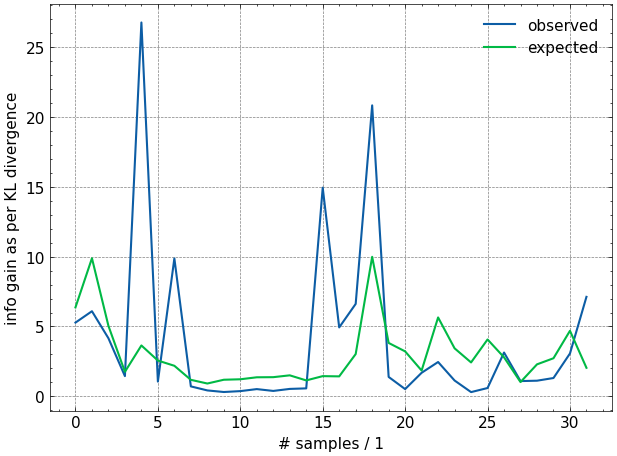

In [14]:
plt.plot(np.arange(len(kldses)), kldses, label="observed")
plt.plot(np.arange(len(kldses)), expected_KLDs, label="expected")
plt.legend()
plt.xlabel("# samples / 1")
plt.ylabel("info gain as per KL divergence")

Text(0, 0.5, 'info gain as per KL divergence')

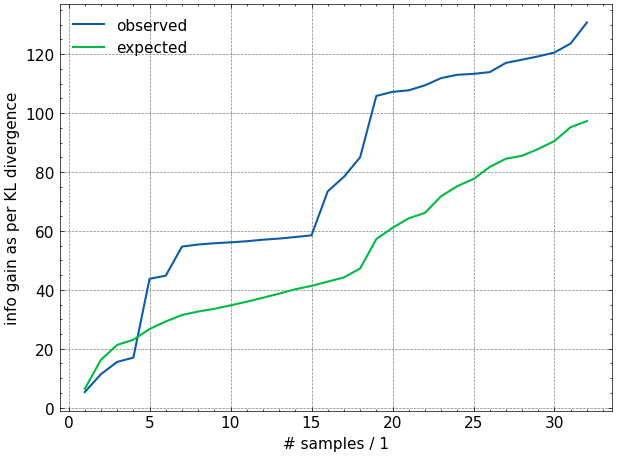

In [15]:
plt.plot(np.arange(len(kldses)) + 1, np.cumsum(kldses), label="observed")
plt.plot(np.arange(len(kldses)) + 1, np.cumsum(expected_KLDs), label="expected")
plt.legend()
plt.xlabel("# samples / 1")
plt.ylabel("info gain as per KL divergence")

Text(0, 0.5, 'info gain as per KL divergence')

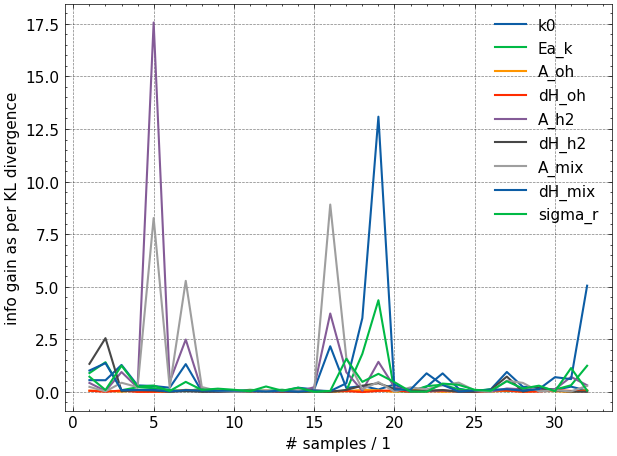

In [16]:
plt.plot(
    np.arange(len(kldses)) + 1,
    info_gains,
    label=[
        "k0",
        "Ea_k",
        "A_oh",
        "dH_oh",
        "A_h2",
        "dH_h2",
        "A_mix",
        "dH_mix",
        "sigma_r",
    ],
)
plt.legend()
plt.xlabel("# samples / 1")
plt.ylabel("info gain as per KL divergence")

In [17]:
cum_info_gains = []
for i in range(0, len(idatas)):
    klds = kl_divergence_between_models(
        idata_new=idatas[i],
        idata_old=idatas[0],
        key_new="posterior",
        key_old="prior",
        var_names=[
            "k0",
            "Ea_k",
            "A_oh",
            "dH_oh",
            "A_h2",
            "dH_h2",
            "A_mix",
            "dH_mix",
            "sigma_r",
        ],
    )
    cum_info_gains.append(klds)
cum_kldses = []
for i, klds in enumerate(cum_info_gains):
    print(klds)
    print(klds.sum())
    cum_kldses.append(klds.sum())

[0.59687087 0.91605821 0.03869898 0.043864   0.38681523 1.41071475
 0.2504204  0.99888661 0.75314604]
5.395475087180798
[0.8714464  2.08439559 0.08713917 0.04392796 0.45304728 0.39913453
 0.31932848 0.59626561 0.93872411]
5.793409138753726
[1.51260656 2.35193385 0.01901289 0.10563836 0.86394581 0.46641302
 0.82258345 0.40933487 0.4176689 ]
6.969137715092025
[2.09866892 2.8040123  0.15810903 0.04359496 1.32052155 0.40070889
 1.22166645 0.3824787  0.4405316 ]
8.87029240842103
[2.66328434 3.00545854 0.0743554  0.07356467 1.96514886 0.52715836
 1.81762651 0.40995033 0.85387505]
11.390422062829316
[2.83760351 3.01928465 0.12071263 0.13535825 1.91888048 0.57221774
 1.74779256 0.40992209 0.82889938]
11.59067129438972
[ 2.79057596e+00  3.11420715e+00  9.65874336e-02 -1.40784879e-03
  1.75914354e+00  4.27298101e-01  1.57919407e+00  3.00412267e-01
  6.40937609e-01]
10.706948281220573
[2.81143486 2.96441248 0.02807659 0.03341937 1.77478208 0.43468749
 1.74739676 0.31858134 0.72096784]
10.83375882

Text(0, 0.5, 'info gain as per KL divergence')

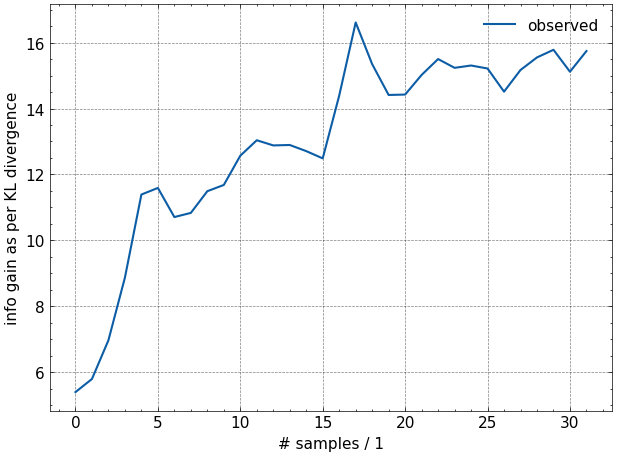

In [18]:
plt.plot(np.arange(len(cum_kldses)), cum_kldses, label="observed")
plt.legend()
plt.xlabel("# samples / 1")
plt.ylabel("info gain as per KL divergence")

## evaluate the agreement with GT parameters

In [19]:
from scipy.stats import gaussian_kde

param_names = {
    "k0": "k0",
    "Ea_k": "EA",
    "A_oh": "A_OH",
    "dH_oh": "H_OH",
    "A_h2": "A_H2",
    "dH_h2": "H_H2",
    "A_mix": "A_mix",
    "dH_mix": "H_mix",
}

param_agreement = xarray.DataArray(
    dims=["iteration", "parameter"],
    coords={
        "iteration": np.arange(len(idatas)),
        "parameter": list(param_names.keys()),
    },
    data=np.zeros((len(idatas), len(param_names))),
)

for i in range(0, len(idatas)):
    for param, name in param_names.items():
        samples = az.extract(
            idatas[i],
            group="posterior",
            var_names=[param],
        ).values
        dist = gaussian_kde(samples)
        point_prob = dist(TRUE_PARAMS[name]) * TRUE_PARAMS[name].abs().numpy()
        param_agreement.loc[i, param] = point_prob.item()

display(param_agreement)

<xarray.DataArray (iteration: 32, parameter: 8)> Size: 2kB
array([[6.59018629e-01, 5.94127566e-01, 3.24909170e-01, 1.49570073e-01,
        1.06907544e-01, 2.77562926e-13, 6.84518682e-01, 3.45744261e+00],
       [1.98698550e-01, 3.55232172e+00, 3.77849389e-01, 1.73500234e-01,
        8.43964413e-02, 2.11416122e-01, 7.20358492e-01, 1.85432197e+00],
       [1.48851337e+00, 4.56128775e+00, 3.57907518e-01, 1.99275648e-01,
        4.76955776e-01, 1.71212691e-01, 7.34607990e-01, 1.66217648e+00],
       [3.04664053e+00, 7.90892433e+00, 3.57259499e-01, 1.90291477e-01,
        6.07457912e-02, 2.44265353e-01, 1.93348468e-01, 1.67434321e+00],
       [5.07577899e+00, 1.18496409e+01, 3.48089569e-01, 1.72292554e-01,
        4.21177538e-02, 1.43811910e-01, 2.00505092e-01, 1.47950121e+00],
       [5.15334605e+00, 1.20052967e+01, 3.68953601e-01, 1.36225645e-01,
        3.07347569e-01, 1.21147377e-01, 8.40225455e-01, 1.40492563e+00],
       [4.19703539e+00, 1.18548544e+01, 4.40411565e-01, 1.65506436e-01,
        2.69689662e+00, 2.24055555e-01, 1.48510099e+00, 1.51284920e+00],
       [4.01267104e+00, 8.30304250e+00, 3.75051400e-01, 1.69955168e-01,
        2.43597010e+00, 2.42680647e-01, 2.61845758e+00, 1.54993448e+00],
       [4.07213288e+00, 9.35500960e+00, 3.87904568e-01, 2.02108351e-01,
        2.69610530e+00, 2.27084104e-01, 2.89884042e+00, 1.66806779e+00],
       [4.38345126e+00, 8.15850319e+00, 3.29001579e-01, 1.49851532e-01,
        2.84395020e+00, 1.72961995e-01, 2.96742675e+00, 1.60425427e+00],
...
       [2.62565338e+00, 7.97432848e+00, 3.25163174e-01, 1.86656344e-01,
        5.69023659e+00, 5.63657430e-02, 4.80146791e+00, 8.75498011e-01],
       [8.39458385e-01, 4.65338425e+00, 3.70131443e-01, 1.91694452e-01,
        5.54331158e+00, 8.08939686e-02, 1.08870018e+00, 1.16625189e+00],
       [1.28207110e+00, 3.06540804e+00, 3.63714383e-01, 1.66513903e-01,
        5.99979756e+00, 9.01634893e-02, 4.15790508e-01, 6.40180587e-01],
       [2.62693438e-01, 5.08597553e+00, 3.65337073e-01, 1.35889641e-01,
        6.16993876e+00, 1.58308088e-01, 7.14456817e-01, 1.06975089e+00],
       [4.10555258e+00, 6.62302729e+00, 3.86193759e-01, 1.78311093e-01,
        5.82994659e+00, 5.93361285e-02, 3.46942901e+00, 1.71579560e+00],
       [8.75850638e+00, 3.80238940e+00, 3.73387792e-01, 1.70524949e-01,
        6.17155850e+00, 2.87472876e-02, 7.74301928e+00, 1.22705717e+00],
       [4.26843052e+00, 5.74739385e+00, 4.05912342e-01, 2.07372423e-01,
        5.07445116e+00, 5.25444622e-02, 7.23197658e+00, 2.01665601e+00],
       [7.02542908e+00, 4.23748172e+00, 3.40068363e-01, 1.47942598e-01,
        3.01586947e+00, 1.62277493e-01, 8.85910683e+00, 5.23813308e-01],
       [1.16981207e+01, 1.16686573e+01, 3.16970473e-01, 1.93058575e-01,
        5.89731097e+00, 1.79352186e-01, 8.08064138e+00, 1.99617674e+00],
       [9.26899258e+00, 1.40630775e+01, 3.47092224e-01, 1.74837671e-01,
        4.81819830e+00, 1.69996318e-01, 5.04505505e+00, 3.07165540e-01]])
Coordinates:
  * iteration  (iteration) int64 256B 0 1 2 3 4 5 6 7 ... 25 26 27 28 29 30 31
  * parameter  (parameter) <U6 192B 'k0' 'Ea_k' 'A_oh' ... 'A_mix' 'dH_mix'

In [20]:
from ipywidgets import interact, Dropdown


@interact(
    key=Dropdown(
        options=list(idatas[0].posterior.data_vars),
        value="k0",
        description="Parameter:",
    ),
)
def interactive(key):
    plt.plot(param_agreement.sel(parameter=key))

interactive(children=(Dropdown(description='Parameter:', options=('k0', 'Ea_k', 'A_oh', 'dH_oh', 'A_h2', 'dH_h…

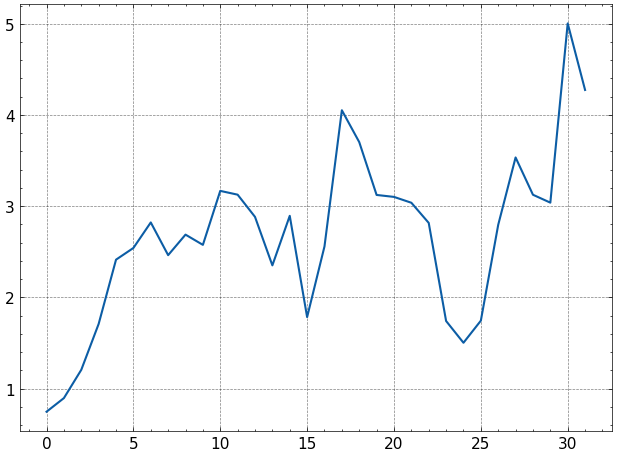

In [21]:
plt.plot(param_agreement.mean(dim="parameter"))

## investigate the parameters

In [22]:
from ipywidgets import Dropdown

print(list(idatas[0].posterior.data_vars))


@interact(
    key=Dropdown(
        options=list(idatas[0].posterior.data_vars),
        value="k0",
        description="Parameter:",
    )
)
def interactive(key):
    az.plot_density(
        [idata for idata in idatas],
        group="posterior",
        var_names=key,
        shade=0.2,
    )

['k0', 'Ea_k', 'A_oh', 'dH_oh', 'A_h2', 'dH_h2', 'A_mix', 'dH_mix', 'sigma_r']


interactive(children=(Dropdown(description='Parameter:', options=('k0', 'Ea_k', 'A_oh', 'dH_oh', 'A_h2', 'dH_h…

In [23]:
@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
    key=Dropdown(
        options=list(idatas[0].posterior.data_vars),
        value="k0",
        description="Parameter:",
    ),
)
def interactive(i, key):
    az.plot_dist_comparison(idatas[i], var_names=[key], figsize=(4, 4))

interactive(children=(IntSlider(value=0, description='Iteration:', max=31), Dropdown(description='Parameter:',…

In [24]:
@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
)
def interactive(i):
    axs = az.plot_pair(
        idatas[i],
        group="posterior",
        var_names=["k0", "Ea_k"],
        kind=["scatter", "kde"],
        point_estimate="median",
        marginals=True,
    ).flatten()
    axs[2].set(
        xlim=(8e-5, 1e-3),
        # xscale="log",
        ylim=(30e3, 130e3),
    )

interactive(children=(IntSlider(value=0, description='Iteration:', max=31), Output()), _dom_classes=('widget-i…

In [25]:
az.summary(idatas[-1], round_to=5)

arviz - WARNING - Shape validation failed: input_shape: (1, 4000), minimum_shape: (chains=2, draws=4)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
k0[0],0.00035,0.00001,0.00033,0.00038,0.00000,0.00000,3960.50246,3712.14925,NaN
Ea_k[0],78774.15625,1670.38562,75706.34375,81947.66406,27.26528,19.12031,3734.83991,3711.99585,NaN
A_oh[0],1.03578,1.31203,0.02161,2.91920,0.02078,0.06161,3730.00804,3919.42846,NaN
dH_oh[0],9786.94434,13029.25098,246.15265,27445.78320,204.58000,969.08533,3930.23638,3881.35747,NaN
A_h2[0],0.42332,0.02925,0.36872,0.47913,0.00051,0.00035,3308.24952,3725.62643,NaN
dH_h2[0],-9470.65234,1512.25867,-12521.32031,-6800.56152,25.53281,18.07220,3489.90913,3837.04136,NaN
A_mix[0],0.92181,0.03685,0.85197,0.99222,0.00058,0.00042,3963.12348,3912.38991,NaN
dH_mix[0],-6748.01465,1554.64490,-9647.49023,-3853.45581,25.41149,17.60619,3732.26317,3824.90373,NaN
sigma_r[0],0.05171,0.00613,0.04071,0.06356,0.00010,0.00008,3730.30204,3893.88385,NaN
